# Comparación de modelos y selección del mejor

En este notebook se resumen las configuraciones probadas de cada modelo y se justifica cuál se escogió:

- **Modelo 1 (Regresión, notebook 03):** predice la nota final G3 (0 a 20). Se mide con MAE, RMSE y varianza explicada.
- **Modelo 2 (Clasificación multiclase, notebook 04):** predice el nivel de riesgo (1 a 4). Se mide con accuracy, precisión, recall, F1 y matriz de confusión.

Las curvas de pérdida de cada configuración están en los notebooks 03 y 04. Aquí se cargan los modelos seleccionados (los mismos que usa la API) y se evalúan otra vez con los 209 estudiantes de test para comprobar sus resultados. No se entrena nada nuevo.

# 1.Importación librerías

In [1]:
import sys
sys.path.append('..') #para poder importar la carpeta src desde notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import load_model
from sklearn.metrics import mean_absolute_error, mean_squared_error, explained_variance_score
from sklearn.metrics import classification_report, confusion_matrix

from src import config
from src.train.model1 import ModeloRegresion
from src.train.model2 import ModeloClasificacion

# 2.Importación de datos y modelos

In [2]:
#Mismos datos procesados que usaron los notebooks 03 y 04
train = pd.read_csv(config.RUTA_PROCESSED / 'train.csv')
test = pd.read_csv(config.RUTA_PROCESSED / 'test.csv')
train.shape, test.shape

((835, 64), (209, 64))

In [3]:
#Objetos de los modelos seleccionados: preparan los datos igual que en sus notebooks
modelo1 = ModeloRegresion(version='A', usar_dropout=True)
X_train_1, X_test_1, y_train_1, y_test_1 = modelo1.preparar_datos(train, test)

modelo2 = ModeloClasificacion(version='A', usar_dropout=False)
X_train_2, X_test_2, y_train_2, y_test_2 = modelo2.preparar_datos(train, test)

In [4]:
#Cargamos los modelos guardados (los mismos que usa la API)
modelo1.modelo = load_model(config.RUTA_MODELS / 'model1.keras')
modelo2.modelo = load_model(config.RUTA_MODELS / 'model2.keras')

# 3.Modelo 1 - Regresión: comparación de configuraciones

In [5]:
#Resultados en test de las configuraciones probadas en el notebook 03
resultados_m1 = pd.DataFrame({
    'Configuración': ['Versión A sin Dropout', 'Versión A con Dropout', 'Versión B sin Dropout', 'Versión B con Dropout', 'Versión B con Dropout, batch 64'],
    'MAE': [1.129, 1.136, 2.683, 2.703, 2.658],
    'RMSE': [1.730, 1.699, 3.678, 3.653, 3.609],
    'Varianza explicada': [0.821, 0.824, 0.191, 0.185, 0.206]})
resultados_m1

,Configuración,MAE,RMSE,Varianza explicada
0,Versión A sin Dropout,1.129,1.730,0.821
1,Versión A con Dropout,1.136,1.699,0.824
2,Versión B sin Dropout,2.683,3.678,0.191
3,Versión B con Dropout,2.703,3.653,0.185
4,"Versión B con Dropout, batch 64",2.658,3.609,0.206


In [6]:
#Comprobamos el modelo seleccionado (Versión A con Dropout) cargado desde models/model1.keras
predicciones_1 = modelo1.predecir(X_test_1)
print('MAE:', mean_absolute_error(y_test_1, predicciones_1))
print('RMSE:', np.sqrt(mean_squared_error(y_test_1, predicciones_1)))
print('Varianza explicada:', explained_variance_score(y_test_1, predicciones_1))

MAE: 1.1357102394104004
RMSE: 1.699235025963717
Varianza explicada: 0.8239449858665466


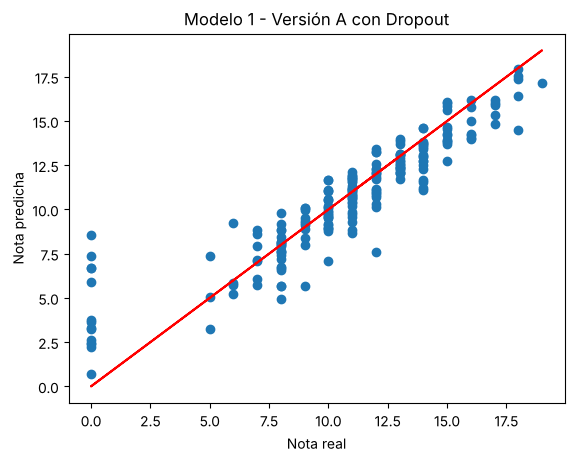

In [7]:
#Visualizar nuestra predicción
plt.scatter(y_test_1, predicciones_1)
plt.xlabel('Nota real')
plt.ylabel('Nota predicha')
#Predicción perfecta
plt.plot(y_test_1, y_test_1, 'r')
plt.title('Modelo 1 - Versión A con Dropout')
plt.show()

**Selección del Modelo 1: Versión A con Dropout.**

- Tiene el menor RMSE (1.70) y la mayor varianza explicada (0.82): comete menos errores grandes.
- Su MAE es casi igual al de la versión sin Dropout (1.14 contra 1.13), pero con Dropout las curvas de loss y val_loss quedan más juntas, es decir, hay menos overfitting.
- La Versión B (sin G1 ni G2) se equivoca unos 2.7 puntos, mucho más. Aun así es mejor que predecir siempre el promedio (MAE 3.0), por lo que sirve como primera señal al inicio del año.

# 4.Modelo 2 - Clasificación: comparación de configuraciones

In [8]:
#Resultados en test de las configuraciones probadas en el notebook 04
resultados_m2 = pd.DataFrame({
    'Configuración': ['Versión A sin Dropout', 'Versión A con Dropout', 'Versión B sin Dropout', 'Versión B con Dropout'],
    'Accuracy': [0.732, 0.679, 0.416, 0.450],
    'Precision': [0.736, 0.683, 0.420, 0.457],
    'Recall': [0.732, 0.679, 0.416, 0.450],
    'F1': [0.733, 0.680, 0.393, 0.427]})
resultados_m2

,Configuración,Accuracy,Precision,Recall,F1
0,Versión A sin Dropout,0.732,0.736,0.732,0.733
1,Versión A con Dropout,0.679,0.683,0.679,0.680
2,Versión B sin Dropout,0.416,0.420,0.416,0.393
3,Versión B con Dropout,0.450,0.457,0.450,0.427


In [9]:
#Comprobamos el modelo seleccionado (Versión A sin Dropout) cargado desde models/model2.keras
predicciones_2 = modelo2.predecir(X_test_2)
etiquetas = ['Sin riesgo (1)', 'Riesgo bajo (2)', 'Riesgo medio (3)', 'Riesgo alto (4)']
print(classification_report(y_test_2, predicciones_2, target_names=etiquetas))

                  precision    recall  f1-score   support

  Sin riesgo (1)       0.78      0.78      0.78        50
 Riesgo bajo (2)       0.57      0.55      0.56        42
Riesgo medio (3)       0.67      0.75      0.71        56
 Riesgo alto (4)       0.88      0.80      0.84        61

        accuracy                           0.73       209
       macro avg       0.72      0.72      0.72       209
    weighted avg       0.74      0.73      0.73       209



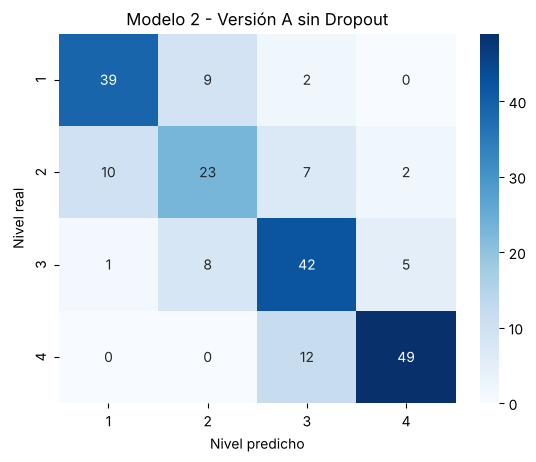

In [10]:
matriz = confusion_matrix(y_test_2, predicciones_2)
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', xticklabels=[1,2,3,4], yticklabels=[1,2,3,4])
plt.xlabel('Nivel predicho')
plt.ylabel('Nivel real')
plt.title('Modelo 2 - Versión A sin Dropout')
plt.show()

**Selección del Modelo 2: Versión A sin Dropout.**

- Tiene la mayor accuracy (73.2 %) y el mayor F1 (0.73). En este modelo el Dropout empeoró los resultados (67.9 %).
- En la matriz de confusión casi todos los errores quedan al lado de la diagonal (se equivoca por un solo nivel) y ningún estudiante de riesgo alto se clasifica como sin riesgo.
- En riesgo alto tiene una precisión de 0.88 y un recall de 0.80: detecta a 49 de los 61 estudiantes que reprueban.
- Sin notas parciales (Versión B) el accuracy baja a 42-45 %. Es mejor que adivinar al azar (25 % con 4 niveles), pero no es suficiente para clasificar con confianza.

# 5.Resumen de los modelos seleccionados

In [11]:
resumen = pd.DataFrame({
    'Modelo 1 - Regresión': ['Nota final G3 (0 a 20)', 'Versión A con Dropout', 'MAE 1.14 / RMSE 1.70', 'Varianza explicada 0.82', '/predict/grade', 'Nota proyectada'],
    'Modelo 2 - Clasificación': ['Nivel de riesgo (1 a 4)', 'Versión A sin Dropout', 'Accuracy 0.73 / F1 0.73', 'Recall riesgo alto 0.80', '/predict/risk_level', 'Alerta y recomendación']},
    index=['Qué predice', 'Configuración escogida', 'Métricas principales', 'Otra métrica', 'Endpoint de la API', 'Uso en el dashboard'])
resumen

,Modelo 1 - Regresión,Modelo 2 - Clasificación
Qué predice,Nota final G3 (0 a 20),Nivel de riesgo (1 a 4)
Configuración escogida,Versión A con Dropout,Versión A sin Dropout
Métricas principales,MAE 1.14 / RMSE 1.70,Accuracy 0.73 / F1 0.73
Otra métrica,Varianza explicada 0.82,Recall riesgo alto 0.80
Endpoint de la API,/predict/grade,/predict/risk_level
Uso en el dashboard,Nota proyectada,Alerta y recomendación


# 6.Conclusión

- Para cada modelo se compararon al menos dos configuraciones (con y sin Dropout, con y sin notas parciales) y se escogió la mejor según sus métricas: **Versión A con Dropout** para el Modelo 1 y **Versión A sin Dropout** para el Modelo 2.
- Los dos modelos resuelven tareas distintas, por eso **se usan juntos** en el sistema: el Modelo 1 da la nota esperada del estudiante y el Modelo 2 da su nivel de riesgo, con el que se activa la alerta y la recomendación en el dashboard.
- En los dos modelos la **Versión A (con G1 y G2)** es claramente mejor, pero solo se puede usar a partir del segundo periodo, cuando ya existen notas parciales. Se recomienda usar la **Versión B** como primera señal al inicio del año y la Versión A cuando ya se tengan notas.
- Limitaciones: los estudiantes con nota final 0 (posible abandono) son los más difíciles de predecir, y al volver a entrenar en otra computadora los resultados pueden variar ligeramente, por eso la API y el dashboard usan los modelos ya guardados en `models/`.